In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 

In [5]:
df = sns.load_dataset("iris")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [9]:
df["species"].unique()

array(['setosa', 'versicolor', 'virginica'], dtype=object)

In [13]:
print(df["species"].value_counts())


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


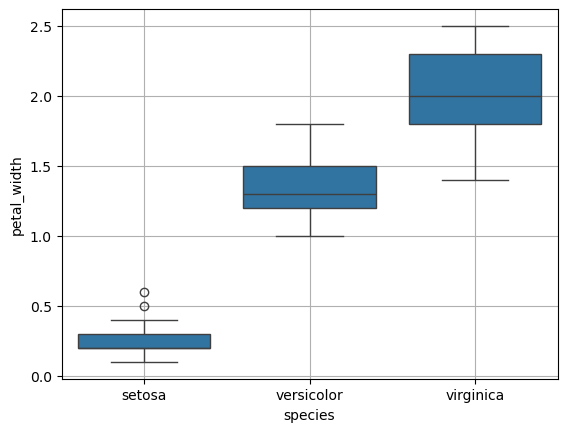

In [30]:
# sns.boxplot(data = df , x= "species" , y = "sepal_length" )
# sns.boxplot(data = df , x= "species" , y = "sepal_width" )
# sns.boxplot(data = df , x= "species" , y = "petal_length" )
sns.boxplot(data = df , x= "species" , y = "petal_width" )
plt.grid(True)

In [31]:
These are ouliers but we should retain as these are not big enough means they are not negative and too much large wwhich are tottaly unacceptable
we will reain them for our testing and real data what if such data comes
# df[(df["species"] == "virginica") & (df["sepal_length"] < 5.5)]
# df[(df["species"] == "setosa") & ((df["sepal_width"] < 2.8) | (df["sepal_width"] > 4.2) )]
# df[(df["species"] == "virginica") & (df["sepal_width"] < 2.5) ]
# df[(df["species"] == "versicolor") & (df["petal_length"] < 3.1) ]
# df[(df["species"] == "setosa") & ((df["petal_length"] < 1.2) | (df["petal_length"] > 1.7) )]
# df[(df["species"] == "setosa") & (df["petal_width"] > 0.4)]

,sepal_length,sepal_width,petal_length,petal_width,species
23,5.1,3.3,1.7,0.5,setosa
43,5.0,3.5,1.6,0.6,setosa


In [42]:
X = df.drop(columns=["species"])
Y = df["species"]

In [46]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
x_train , x_test , y_train , y_test = train_test_split(X,Y,test_size=0.20,random_state = 101)
scale = StandardScaler()
x_train_scaled = scale.fit_transform(x_train)
x_test_scaled = scale.transform(x_test)

In [53]:
model=LogisticRegression(max_iter=1000)
model.fit(x_train_scaled,y_train)
y_pred = model.predict(x_test_scaled)

In [54]:
from sklearn.metrics import accuracy_score , precision_score , recall_score
accuracy = accuracy_score(y_test , y_pred)
print(f"Accuracy score is {accuracy*100} percent ")

Accuracy score is 96.66666666666667 percent 


In [57]:
# KNN
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors = 7)
model.fit(x_train_scaled,y_train)
y_pred = model.predict(x_test_scaled)
from sklearn.metrics import accuracy_score , precision_score , recall_score
accuracy = accuracy_score(y_test , y_pred)
print(f"Accuracy score is {accuracy*100} percent ")

Accuracy score is 100.0 percent 


In [58]:
## Cross validation 
from sklearn.model_selection import GridSearchCV
knn = KNeighborsClassifier()
neighbors = {"n_neighbors":[1,3,5,7,9]}
model = GridSearchCV(
    estimator = knn,
    param_grid = neighbors,
    cv = 5,
    scoring = "accuracy"
)
model.fit(x_train_scaled,y_train)
y_pred = model.predict(x_test_scaled)
from sklearn.metrics import accuracy_score , precision_score , recall_score
accuracy = accuracy_score(y_test , y_pred)
print(f"Best neighbors value is {model.best_params_}")
print(f"Accuracy score is {accuracy*100} percent ")

Best neighbors value is {'n_neighbors': 5}
Accuracy score is 96.66666666666667 percent 


In [60]:
## Pipeline 
from sklearn.pipeline import Pipeline
pipe = Pipeline([('scaler',StandardScaler()),('knn',KNeighborsClassifier())])
neighbors = {"knn__n_neighbors":[1,3,5,7,9]}
model = GridSearchCV(
    estimator = pipe,
    param_grid = neighbors,
    cv = 5,
    scoring = "accuracy"
)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)
from sklearn.metrics import accuracy_score , precision_score , recall_score
accuracy = accuracy_score(y_test , y_pred)
print(f"Best neighbors value is {model.best_params_}")
print(f"Accuracy score is {accuracy*100} percent ")
print("recall score: ", recall_score(y_test, y_pred))
print("accuracy score: ", accuracy_score(y_test, y_pred))
print("precision score: ", precision_score(y_test, y_pred))

Best neighbors value is {'knn__n_neighbors': 5}
Accuracy score is 96.66666666666667 percent 


ValueError: Target is multiclass but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted'].